In [130]:
import pandas as pd

df = pd.read_csv("./ia_tweets.csv")

df.head()

,ID,text,polarity,favorite_count,retweet_count,user_followers_count,user_friends_count,user_favourites_count,user_statuses_count,user_verified,user_has_extended_profile,user_is_translator,user_protected,user_default_profile
0,0,Comentaba en una charla sobre IA que el proble...,N,21,7,15936,2395,66945,68578,0,1,0,0,0
1,1,"@alvaropons Eso es imposible. Y sí, va a gener...",N,1,0,685,851,169490,128555,0,1,0,0,1
2,2,@alvaropons Lo disruptivo es que tras años de ...,NEU,1,0,685,851,169490,128555,0,1,0,0,1
3,3,"@alvaropons ¿""Prohibición del uso comercial de...",N,0,0,4877,538,6123,3156,0,1,0,0,0
4,4,@santoroydonoso Cómo se está estudiando prohib...,NEU,0,0,15936,2395,66945,68578,0,1,0,0,0


In [131]:
df.dtypes

ID                           int64
text                           str
polarity                       str
favorite_count               int64
retweet_count                int64
user_followers_count         int64
user_friends_count           int64
user_favourites_count        int64
user_statuses_count          int64
user_verified                int64
user_has_extended_profile    int64
user_is_translator           int64
user_protected               int64
user_default_profile         int64
dtype: object

In [132]:
from langdetect import detect, DetectorFactory

DetectorFactory.seed = 0

df['idioma'] = df['text'].apply(detect)

df = df[df["idioma"] == "es"]

df = df.drop(columns=["ID","user_has_extended_profile", "user_is_translator", "user_protected", "idioma"])

In [133]:
def filtrar_por_polaridad(field):
    return df[df["polarity"] == field]

cant_negativos = len(filtrar_por_polaridad("N"))
cant_neutros = len(filtrar_por_polaridad("NEU"))
cant_positivos =  len(filtrar_por_polaridad("P"))

print('Cantidad de tweets: ', len(df))
print('Tweets Negativos: ', cant_negativos, ', Neutros' , cant_neutros,', Positivos', cant_positivos)

# Cantidad de datos desbalanceada, se tiene mucho mas datos neutros que negativos o positivos.

Cantidad de tweets:  3660
Tweets Negativos:  551 , Neutros 2417 , Positivos 692


In [134]:
cantidad_na = df.isna().sum()
print(cantidad_na)

#(cantidad_negativos_columna("favorite_count"))

# No hay nulls o valores

text                     0
polarity                 0
favorite_count           0
retweet_count            0
user_followers_count     0
user_friends_count       0
user_favourites_count    0
user_statuses_count      0
user_verified            0
user_default_profile     0
dtype: int64


In [135]:
cantidad_negativos = (df.select_dtypes(include='number') < 0).sum()
print(cantidad_negativos)

favorite_count           0
retweet_count            0
user_followers_count     0
user_friends_count       0
user_favourites_count    0
user_statuses_count      0
user_verified            0
user_default_profile     0
dtype: int64


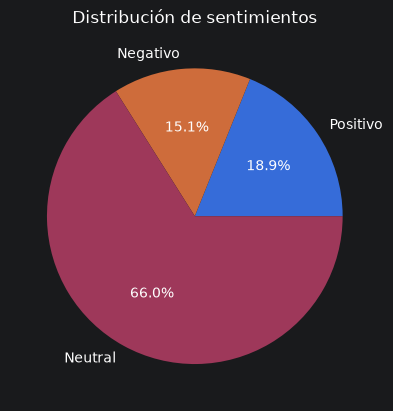

In [136]:
import matplotlib.pyplot as plt

# Datos
clases = ['Positivo', 'Negativo', 'Neutral']
cantidades = [cant_positivos, cant_negativos, cant_neutros]

# Crear gráfico
plt.pie(cantidades, labels=clases, autopct='%1.1f%%')
plt.title('Distribución de sentimientos')
plt.show()

4.1519125683060105
2243
0


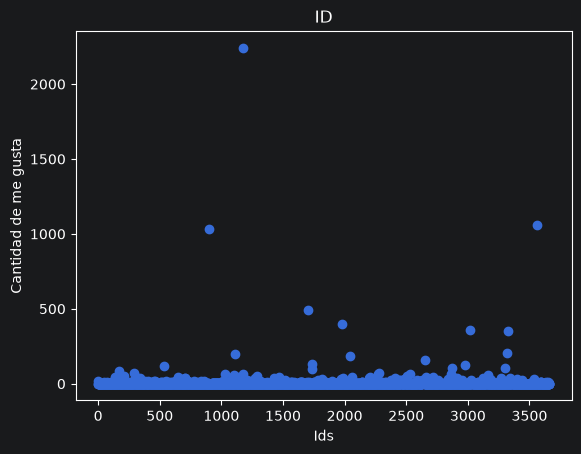

In [137]:
print(df["favorite_count"].mean())
print(df["favorite_count"].max())
print(df["favorite_count"].min())

plt.scatter(range(0,len(df)), df['favorite_count'])

plt.xlabel('Ids')
plt.ylabel('Cantidad de me gusta')
plt.title('ID')

plt.show()

0.9606557377049181
502
0


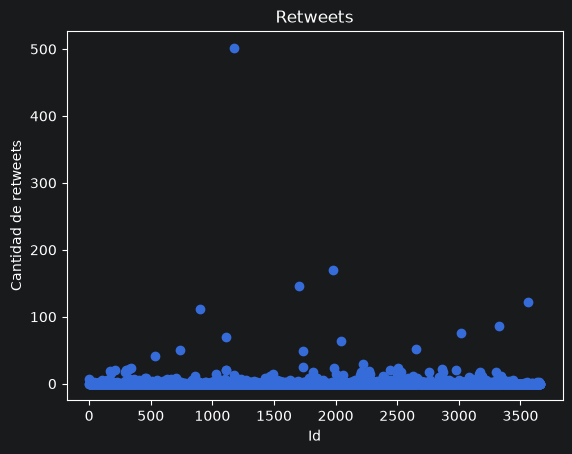

In [138]:
print(df["retweet_count"].mean())
print(df["retweet_count"].max())
print(df["retweet_count"].min())

plt.scatter(range(0,len(df)), df['retweet_count'])

plt.xlabel('Id')
plt.ylabel('Cantidad de retweets')
plt.title('Retweets')

plt.show()

Cantidad de tweets positivo con interaccion:  172
Cantidad de tweets negativos con interaccion:  139
Media de interacciones en positivos:  6.726878612716763
Media de interacciones en negativos:  3.8747731397459164


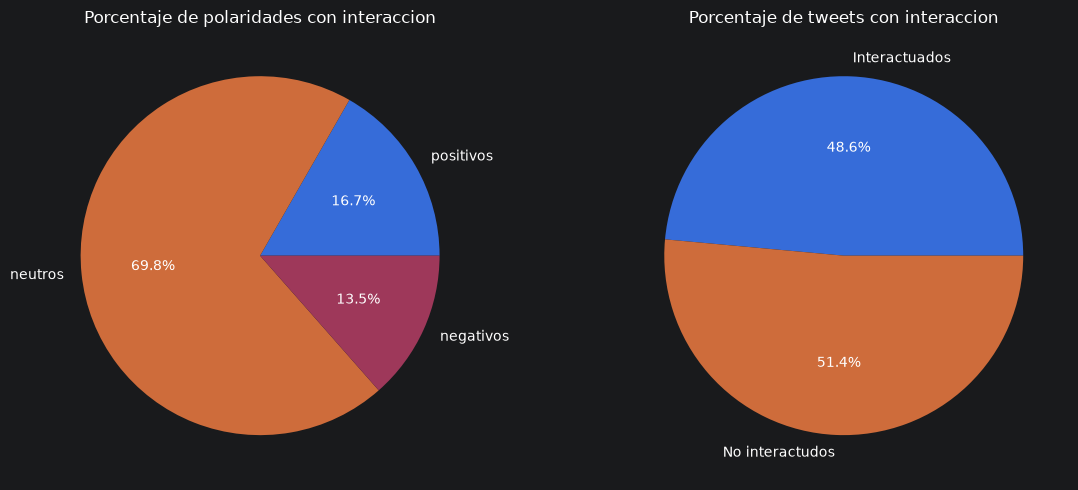

In [139]:
df['tweet_interactions'] = df['favorite_count'] + df['retweet_count']

tweets_con_interaccion = (df['tweet_interactions'] > 0).sum()
tweets_sin_interaccion = (df['tweet_interactions'] == 0).sum()

positivos_con_interaccion = (df[df['polarity'] == 'P']['tweet_interactions'] > 1).sum()
neutros_con_interaccion = (df[df['polarity'] == 'NEU']['tweet_interactions'] > 1).sum()
negativos_con_interaccion = (df[df['polarity'] == 'N']['tweet_interactions'] > 1).sum()
interaccion_positivos_media = df[df['polarity'] == 'P']['tweet_interactions'].mean()
interaccion_negativos_media = df[df['polarity'] == 'N']['tweet_interactions'].mean()

print("Cantidad de tweets positivo con interaccion: ", positivos_con_interaccion)
print("Cantidad de tweets negativos con interaccion: ", negativos_con_interaccion)
print("Media de interacciones en positivos: ", interaccion_positivos_media)
print("Media de interacciones en negativos: ", interaccion_negativos_media)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].pie([positivos_con_interaccion, neutros_con_interaccion, negativos_con_interaccion], labels=["positivos", "neutros", "negativos"], autopct='%1.1f%%')
ax[0].set_title('Porcentaje de polaridades con interaccion')

ax[1].pie([tweets_con_interaccion, tweets_sin_interaccion],
  labels=["Interactuados", "No interactudos"], autopct='%1.1f%%')
ax[1].set_title('Porcentaje de tweets con interaccion')

plt.tight_layout()
plt.show()

In [140]:
 #text
#polarity
#favorite_count
#retweet_count
#user_followers_count
#user_friends_count
#user_favourites_count         TEST (Likes que dio)
#user_statuses_count           TEST (Publicaciones y comentarios suyos)
#user_verified                 TEST
#user_default_profile          TEST (Pagina de perfil default)

import unicodedata

def contar_emojis(texto):
    return sum(1 for caracter in str(texto) if unicodedata.category(caracter) == 'So')

df["length"] = df['text'].apply(lambda texto: len(texto.split()))
df["hashtag_count"] = df['text'].apply(lambda texto: texto.count('#'))
df["mention_count"] = df['text'].apply(lambda texto: texto.count('@'))
df["url_count"] = df['text'].apply(lambda texto: texto.count('http'))
df["interrogation_count"] = df['text'].apply(lambda texto: texto.count('?') )
df["exclamation_count"] = df['text'].apply(lambda texto: texto.count('!'))
df['emoji_count'] = df['text'].apply(contar_emojis)

# :url: :mencion:

#Campos extra
#Longitud (palabras)
#Cantidad de hashtags
#Cantidad de usuarios mencionados
#Cantidad de emojis
#Cantidad de urls
#Cantidad de signos de exclamacion
#Cantidad de signos de interrogacion

In [141]:
df["text"] = df["text"].str.replace(r"http\S+|www\.\S+", "URL", regex=True)
df["text"] = df["text"].str.replace(r"@\w+", "MENCION", regex=True)

df.head()

,text,polarity,favorite_count,retweet_count,user_followers_count,user_friends_count,user_favourites_count,user_statuses_count,user_verified,user_default_profile,tweet_interactions,length,hashtag_count,mention_count,url_count,interrogation_count,exclamation_count,emoji_count
0,Comentaba en una charla sobre IA que el proble...,N,21,7,15936,2395,66945,68578,0,0,28,44,0,0,1,0,0,0
1,"MENCION Eso es imposible. Y sí, va a generar u...",N,1,0,685,851,169490,128555,0,1,1,41,0,1,0,0,0,0
2,MENCION Lo disruptivo es que tras años de deci...,NEU,1,0,685,851,169490,128555,0,1,1,39,0,1,0,0,0,0
3,"MENCION ¿""Prohibición del uso comercial de las...",N,0,0,4877,538,6123,3156,0,0,0,17,0,1,0,1,0,0
4,MENCION Cómo se está estudiando prohibir chatG...,NEU,0,0,15936,2395,66945,68578,0,0,0,39,0,1,0,1,0,0


In [142]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["polarity"])
y = df["polarity"]

# 60% para train y 40% para test y validacion
X_train, X_test_val, y_train, y_test_val = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# Segunda división: separar test y validación
X_test, X_val, y_test, y_val = train_test_split(
    X_test_val, y_test_val,
    test_size=0.5,
    random_state=42,
    stratify=y_test_val
)

print(len(X_train)/len(df))

0.6


In [143]:
#from sklearn.preprocessing import StandardScaler

#number_columns = ["favorite_count","retweet_count","user_followers_count", "user_friends_count", "user_favourites_count", "user_statuses_count", "tweet_interactions", "hashtag_count", "mention_count"]

#scaler = StandardScaler()

#X_train[number_columns] = scaler.fit_transform(X_train[number_columns]) #No es necesario para RF pero lo dejo por consistencia

#y_train = pd.get_dummies(y_train, columns=["polarity"], dtype=int, drop_first=True)

#X_train.head()
#y_train.head()

In [144]:
from sklearn.base import BaseEstimator, TransformerMixin
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer, SnowballStemmer
import string

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt_tab')

PUNCT = set(string.punctuation) | set("¿¡«»“”‘’…")
# Palabras que NO se eliminan aunque estén en la lista de stopwords
KEEP = {"no", "ni", "sin", "nunca", "tampoco", "nada", "contra", "muy", "pero", "más", "menos"} #Mejores resultados con KEEP puesto
STOP_WORDS = set(stopwords.words('spanish')) - KEEP

class TextCleaner(BaseEstimator, TransformerMixin):
    def __init__(self, method=None, ngram_range=(1, 1), remove_stopwords=True):
        self.method = method                      # None, "stem" o "lemma"
        self.ngram_range = ngram_range            # (1, 1) = solo palabras sueltas
        self.remove_stopwords = remove_stopwords  # True = saca stopwords (salvo KEEP)

    def fit(self, X, y=None):
        if self.method not in (None, "stem", "lemma"):
            raise ValueError("method debe ser None, 'stem' o 'lemma'")
        return self

    def _is_valid(self, token):
        if not token.strip() or all(c in PUNCT for c in token):
            return False
        if self.remove_stopwords and token in STOP_WORDS:
            return False
        return True

    def _ngrams(self, tokens):
        n_min, n_max = self.ngram_range
        out = []
        for n in range(n_min, n_max + 1):
            out += ["_".join(tokens[i:i + n]) for i in range(len(tokens) - n + 1)]
        return out

    def transform(self, X):
        X = list(X)

        if self.method == "lemma":
            import spacy
            nlp = spacy.load("es_core_news_sm", disable=["parser", "ner"])
            token_lists = []
            for doc in nlp.pipe(X):
                # se filtra por el texto original y después se toma el lema
                token_lists.append([t.lemma_.lower() for t in doc if self._is_valid(t.text.lower())])
        else:
            token_lists = [
                [t for t in nltk.word_tokenize(text.lower(), language="spanish") if self._is_valid(t)]
                for text in X
            ]
            if self.method == "stem":
                stemmer = SnowballStemmer("spanish")
                token_lists = [[stemmer.stem(t) for t in toks] for toks in token_lists]

        return [" ".join(self._ngrams(toks)) for toks in token_lists]

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\nicky\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\nicky\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\nicky\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [145]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

cleaner = TextCleaner("lemma")

vectores = cleaner.transform(df["text"])
vectorizer_BoW = CountVectorizer()
vectorizer_Tfidf = TfidfVectorizer()


matriz_BoW = vectorizer_BoW.fit_transform(vectores)
matriz_Tfidf = vectorizer_Tfidf.fit_transform(vectores)

print(vectorizer_BoW.get_feature_names_out())
print(matriz_BoW.toarray()[0])
#print(vectores_Tfidf.shape)

['00' '000' '003' ... '𝙀𝙣𝙩𝙧𝙚𝙥𝙖𝙧𝙦𝙪𝙚𝙨' '𝙈𝙤𝙣𝙩𝙚𝙨𝙪𝙧' '𝙈𝙤𝙣𝙩𝙞𝙚𝙡']
[0 0 0 ... 0 0 0]


In [146]:
from sentence_transformers import SentenceTransformer # <- Estandar para Embeddings

class EmbeddingTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, model_name='all-MiniLM-L6-v2'):
        self.model_name = model_name
        self.model = None

    def fit(self, X, y=None):
        # Cargamos el modelo aquí para evitar errores de serialización
        if self.model is None:
            self.model = SentenceTransformer(self.model_name)
        return self

    def transform(self, X):
        # Convertimos la lista de textos en una matriz de vectores (Embeddings)
        # Esto implementa implícitamente el "Mean Pooling"
        return self.model.encode(list(X), show_progress_bar=False)

embedding = EmbeddingTransformer()

In [147]:
embedding.fit(df["text"])
text = embedding.transform(df["text"])

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6919.08it/s]


 ### Principales hiperparámetros de RandomForestClassifier

| Hiperparámetro | Valor por default | ¿Por qué afecta al rendimiento? |
|---|---|---|
| `max_depth` | None | La profundidad máxima del árbol. Si es None, los nodos se expanden hasta que todas las hojas sean puras o hasta que todas las hojas contengan menos de min_samples_split muestras. |
| `min_samples_leaf` | 1 | El número mínimo de muestras requerido en un nodo hoja. Un punto de división a cualquier profundidad solo se considerará si deja al menos `min_samples_leaf` muestras de entrenamiento tanto en la rama izquierda como en la derecha. Esto puede tener el efecto de suavizar el modelo, especialmente en problemas de regresión. |
| `min_samples_split` | 2 | El número mínimo de muestras requerido para dividir un nodo interno. |
| `criterion` | `gini` | La función para medir la calidad de una división. Los criterios admitidos son «gini» (para la impureza de Gini) y «log_loss» o «entropy» (ambos para la ganancia de información de Shannon); véase la formulación matemática. |
| `max_features` | `sqrt` | La cantidad de características a tener en cuenta al buscar la mejor división. |
| `max_leaf_nodes` | None | Cultiva árboles con max_leaf_nodes en orden de mejor a mejor. Los mejores nodos se definen como la reducción relativa de impurezas. Si es None, el número de nodos hoja es ilimitado. |

In [148]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone

num_cols = [
    "favorite_count", "retweet_count", "user_followers_count",
    "user_friends_count", "user_favourites_count", "user_statuses_count",
    "tweet_interactions", "hashtag_count", "mention_count", "url_count",
    "exclamation_count", "interrogation_count", "length", "emoji_count"
]

text_bow = Pipeline([
    ("cleaner", TextCleaner("lemma")),
    ("vectorizer", CountVectorizer()),
])
text_tfidf = Pipeline([
    ("cleaner", TextCleaner("lemma")),
    ("vectorizer", TfidfVectorizer()),
])

preprocesador = ColumnTransformer([
    ("text", text_bow, "text"),
    ("num", StandardScaler(), num_cols) #En teoria no hacen falta en RF pero lo pruebo
])

pipeline_Bow_y_TFidf = Pipeline([
    ("pre", preprocesador),
    ('classifier', RandomForestClassifier(random_state=42))
])

# Parámetros a tunear
param_grid = [
    # Opción 3: Random Forest
    {
        'pre__text__cleaner__method': [None, 'stem', 'lemma'],
        'pre__text__vectorizer': [CountVectorizer(), TfidfVectorizer()],
        'pre__text__cleaner__ngram_range': [(1,1), (1,2)],
        'classifier': [RandomForestClassifier(random_state=42)],
        'classifier__n_estimators': [100, 200], #saco 300 para probar
        'classifier__criterion': ['gini', 'entropy'], #Saco log_loss porque nunca es el mejor
        #'classifier__max_depth': [None, 10, 20], Siempre None es mejor
        'classifier__min_samples_split': [2, 5],
        'classifier__min_samples_leaf': [1, 2],
        'classifier__max_features': ['sqrt', 'log2'],
        #'classifier__max_leaf_nodes': [None, 50, 100],Siempre None es mejor
        #'classifier__min_impurity_decrease': [0.0, 0.001, 0.01],
        #'classifier__ccp_alpha': [0.0, 0.001, 0.01],
        #'classifier__min_weight_fraction_leaf': [0.0, 0.01, 0.05],
        'classifier__class_weight': ['balanced'], #Siempre balanced es mejor
    }, {
    'classifier__n_estimators': [100, 200], #300 lo saco para probar
    'classifier__criterion': ['gini', 'entropy'],
    #'classifier__max_depth': [None, 10, 20],
    'classifier__min_samples_split': [2, 5],
    'classifier__min_samples_leaf': [1, 2],
    'classifier__max_features': ['sqrt', 'log2'],
    #'classifier__max_leaf_nodes': [None, 50, 100],
    #'classifier__min_impurity_decrease': [0.0, 0.001, 0.01],
    #'classifier__ccp_alpha': [0.0, 0.001, 0.01],
    #'classifier__min_weight_fraction_leaf': [0.0, 0.01, 0.05],
    'classifier__class_weight': ['balanced'] #Siempre balanced es mejor
}
]

In [149]:
# Ejecución del Grid Search optimizando ROC
grid_search_rf = GridSearchCV(pipeline_Bow_y_TFidf, param_grid, cv=3, scoring='roc_auc_ovr', n_jobs=1, verbose=1)
grid_search_rf.fit(X_train, y_train)
print("Mejores parámetros:", grid_search_rf.best_params_)
print("Mejor ROC:", grid_search_rf.best_score_)

Fitting 3 folds for each of 416 candidates, totalling 1248 fits
Mejores parámetros: {'classifier': RandomForestClassifier(random_state=42), 'classifier__class_weight': 'balanced', 'classifier__criterion': 'entropy', 'classifier__max_features': 'log2', 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 200, 'pre__text__cleaner__method': 'stem', 'pre__text__cleaner__ngram_range': (1, 1), 'pre__text__vectorizer': CountVectorizer()}
Mejor ROC: 0.7746003846953428


VALIDACIÓN - RANDOM FOREST
ROC-AUC OvR (macro): 0.8079
Accuracy: 0.7309

Reporte de clasificación:
              precision    recall  f1-score   support

           N     0.6000    0.3000    0.4000       110
         NEU     0.7571    0.8841    0.8157       483
           P     0.6637    0.5396    0.5952       139

    accuracy                         0.7309       732
   macro avg     0.6736    0.5745    0.6036       732
weighted avg     0.7158    0.7309    0.7113       732



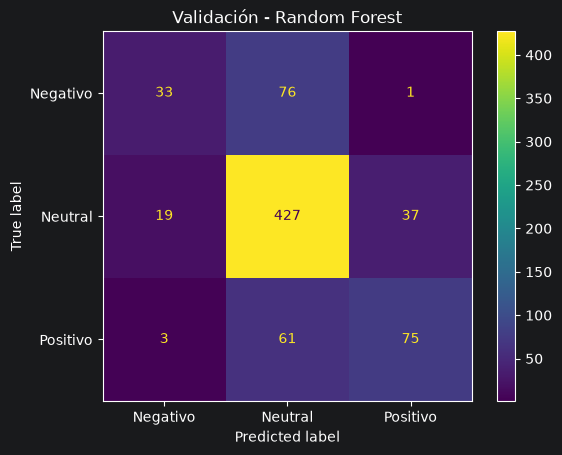


TESTEO FINAL - RANDOM FOREST CON BoW y TF-idf
ROC-AUC OvR (macro): 0.8004
Accuracy: 0.7077

Reporte de clasificación:
              precision    recall  f1-score   support

           N     0.5507    0.3455    0.4246       110
         NEU     0.7469    0.8595    0.7992       484
           P     0.6038    0.4638    0.5246       138

    accuracy                         0.7077       732
   macro avg     0.6338    0.5562    0.5828       732
weighted avg     0.6904    0.7077    0.6912       732



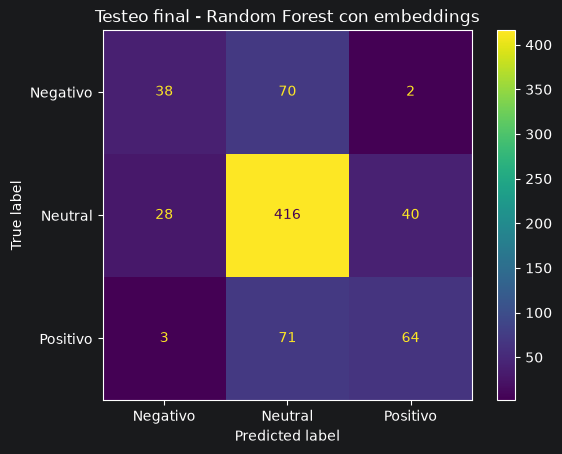

In [150]:
from sklearn.metrics import (
    f1_score,
    roc_auc_score,
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt


mejor_modelo_rf = grid_search_rf.best_estimator_

# Orden de las clases para calcular ROC-AUC
clases = ["N", "NEU", "P"]

# ==============================
# VALIDACIÓN
# ==============================

print("=" * 50)
print("VALIDACIÓN - RANDOM FOREST")
print("=" * 50)

y_pred_val = mejor_modelo_rf.predict(X_val)
y_proba_val = mejor_modelo_rf.predict_proba(X_val)

roc_auc_val = roc_auc_score(
    y_val,
    y_proba_val,
    labels=clases,
    multi_class="ovr",
    average="macro"
)

print(f"ROC-AUC OvR (macro): {roc_auc_val:.4f}")
print(f"Accuracy: {accuracy_score(y_val, y_pred_val):.4f}")

print("\nReporte de clasificación:")
print(classification_report(
    y_val,
    y_pred_val,
    labels=clases,
    digits=4,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_val,
    labels=clases,
    display_labels=["Negativo", "Neutral", "Positivo"]
)
plt.title("Validación - Random Forest")
plt.show()


# ==============================
# TESTEO FINAL
# ==============================

print("\n" + "=" * 50)
print("TESTEO FINAL - RANDOM FOREST CON BoW y TF-idf")
print("=" * 50)

y_pred_test = mejor_modelo_rf.predict(X_test)
y_proba_test = mejor_modelo_rf.predict_proba(X_test)

roc_auc_test = roc_auc_score(
    y_test,
    y_proba_test,
    labels=clases,
    multi_class="ovr",
    average="macro"
)

print(f"ROC-AUC OvR (macro): {roc_auc_test:.4f}")
print(f"Accuracy: {accuracy_score(y_test, y_pred_test):.4f}")

print("\nReporte de clasificación:")
print(classification_report(
    y_test,
    y_pred_test,
    labels=clases,
    digits=4,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_test,
    labels=clases,
    display_labels=["Negativo", "Neutral", "Positivo"]
)
plt.title("Testeo final - Random Forest con embeddings")
plt.show()

In [155]:
mejor_modelo_dt = grid_search_rf.best_estimator_
mejor_pre = mejor_modelo_dt.named_steps["pre"]
mejor_rf = mejor_modelo_dt.named_steps["classifier"]

In [157]:
from sklearn.multiclass import OneVsOneClassifier
from sklearn import set_config

set_config(display="text")

modelo_ovo = Pipeline([
    ("pre", clone(mejor_pre)),
    ("classifier", OneVsOneClassifier(
        clone(mejor_rf)
    ))
])

modelo_ovo.fit(X_train, y_train)

Pipeline(steps=[('pre',
                 ColumnTransformer(transformers=[('text',
                                                  Pipeline(steps=[('cleaner',
                                                                   TextCleaner(method='stem')),
                                                                  ('vectorizer',
                                                                   CountVectorizer())]),
                                                  'text'),
                                                 ('num', StandardScaler(),
                                                  ['favorite_count',
                                                   'retweet_count',
                                                   'user_followers_count',
                                                   'user_friends_count',
                                                   'user_favourites_count',
                                                   'user_statuses_count',
     

VALIDACIÓN - RANDOM FOREST OvO
Accuracy: 0.7295
F1 macro: 0.5601

Reporte de clasificación:
              precision    recall  f1-score   support

           N     0.5938    0.1727    0.2676       110
         NEU     0.7380    0.9213    0.8195       483
           P     0.7216    0.5036    0.5932       139

    accuracy                         0.7295       732
   macro avg     0.6845    0.5325    0.5601       732
weighted avg     0.7132    0.7295    0.6936       732



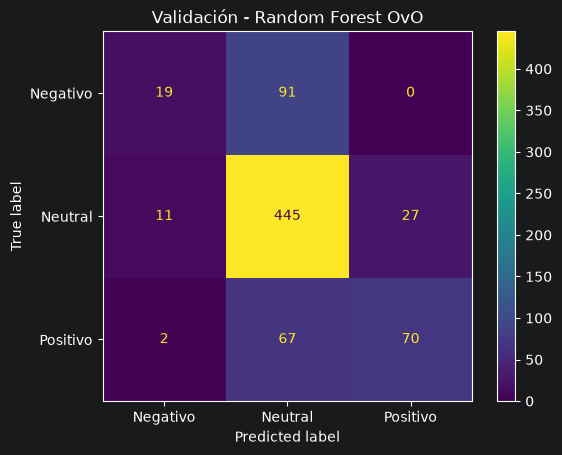


TESTEO FINAL - RANDOM FOREST OvO
Accuracy: 0.7240
F1 macro: 0.5740

Reporte de clasificación:
              precision    recall  f1-score   support

           N     0.6078    0.2818    0.3851       110
         NEU     0.7399    0.9112    0.8167       484
           P     0.6824    0.4203    0.5202       138

    accuracy                         0.7240       732
   macro avg     0.6767    0.5378    0.5740       732
weighted avg     0.7092    0.7240    0.6959       732



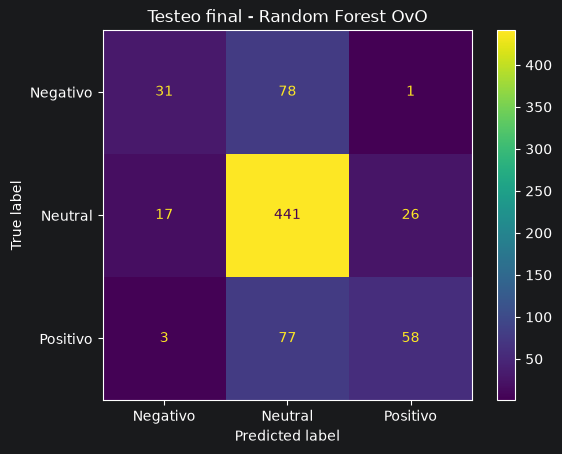

In [159]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

clases = ["N", "NEU", "P"]

# ==============================
# VALIDACIÓN
# ==============================

print("=" * 50)
print("VALIDACIÓN - RANDOM FOREST OvO")
print("=" * 50)

y_pred_val = modelo_ovo.predict(X_val)

print(f"Accuracy: {accuracy_score(y_val, y_pred_val):.4f}")
print(f"F1 macro: {f1_score(y_val, y_pred_val, labels=clases, average='macro', zero_division=0):.4f}")

print("\nReporte de clasificación:")
print(classification_report(
    y_val,
    y_pred_val,
    labels=clases,
    digits=4,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_val,
    labels=clases,
    display_labels=["Negativo", "Neutral", "Positivo"]
)
plt.title("Validación - Random Forest OvO")
plt.show()


# ==============================
# TESTEO FINAL
# Ejecutar una vez elegida la estrategia
# ==============================

print("\n" + "=" * 50)
print("TESTEO FINAL - RANDOM FOREST OvO")
print("=" * 50)

y_pred_test = modelo_ovo.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred_test):.4f}")
print(f"F1 macro: {f1_score(y_test, y_pred_test, labels=clases, average='macro', zero_division=0):.4f}")

print("\nReporte de clasificación:")
print(classification_report(
    y_test,
    y_pred_test,
    labels=clases,
    digits=4,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_test,
    labels=clases,
    display_labels=["Negativo", "Neutral", "Positivo"]
)
plt.title("Testeo final - Random Forest OvO")
plt.show()

In [160]:
# Modelo 3: One-vs-Rest (One-vs-All)
from sklearn.multiclass import OneVsRestClassifier

modelo_ova = Pipeline([
    ("pre", clone(mejor_pre)),
    ("classifier", OneVsRestClassifier(
        clone(mejor_rf)
    ))
])

modelo_ova.fit(X_train, y_train)

Pipeline(steps=[('pre',
                 ColumnTransformer(transformers=[('text',
                                                  Pipeline(steps=[('cleaner',
                                                                   TextCleaner(method='stem')),
                                                                  ('vectorizer',
                                                                   CountVectorizer())]),
                                                  'text'),
                                                 ('num', StandardScaler(),
                                                  ['favorite_count',
                                                   'retweet_count',
                                                   'user_followers_count',
                                                   'user_friends_count',
                                                   'user_favourites_count',
                                                   'user_statuses_count',
     

VALIDACIÓN - RANDOM FOREST
ROC-AUC OvR (macro): 0.8210
Accuracy: 0.7391

Reporte de clasificación:
              precision    recall  f1-score   support

           N     0.6207    0.1636    0.2590       110
         NEU     0.7382    0.9400    0.8270       483
           P     0.7841    0.4964    0.6079       139

    accuracy                         0.7391       732
   macro avg     0.7143    0.5333    0.5646       732
weighted avg     0.7293    0.7391    0.7000       732



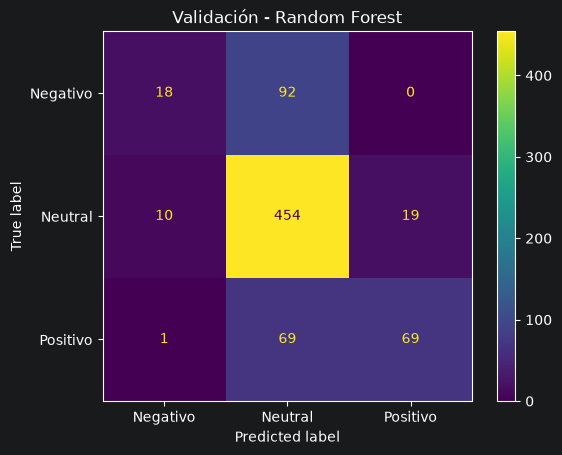


TESTEO FINAL - RANDOM FOREST CON BoW y TF-idf
ROC-AUC OvR (macro): 0.8072
Accuracy: 0.7186

Reporte de clasificación:
              precision    recall  f1-score   support

           N     0.6000    0.2455    0.3484       110
         NEU     0.7311    0.9215    0.8154       484
           P     0.6883    0.3841    0.4930       138

    accuracy                         0.7186       732
   macro avg     0.6732    0.5170    0.5523       732
weighted avg     0.7034    0.7186    0.6844       732



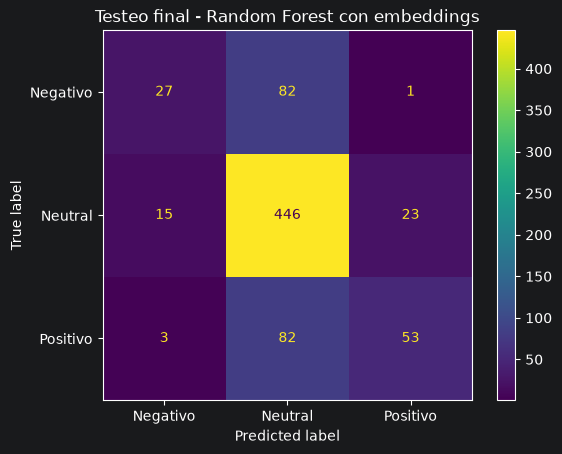

In [161]:
# Orden de las clases para calcular ROC-AUC
clases = ["N", "NEU", "P"]

# ==============================
# VALIDACIÓN
# ==============================

print("=" * 50)
print("VALIDACIÓN - RANDOM FOREST")
print("=" * 50)

y_pred_val = modelo_ova.predict(X_val)
y_proba_val = modelo_ova.predict_proba(X_val)

roc_auc_val = roc_auc_score(
    y_val,
    y_proba_val,
    labels=clases,
    multi_class="ovr",
    average="macro"
)

print(f"ROC-AUC OvR (macro): {roc_auc_val:.4f}")
print(f"Accuracy: {accuracy_score(y_val, y_pred_val):.4f}")

print("\nReporte de clasificación:")
print(classification_report(
    y_val,
    y_pred_val,
    labels=clases,
    digits=4,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_val,
    labels=clases,
    display_labels=["Negativo", "Neutral", "Positivo"]
)
plt.title("Validación - Random Forest")
plt.show()


# ==============================
# TESTEO FINAL
# ==============================

print("\n" + "=" * 50)
print("TESTEO FINAL - RANDOM FOREST CON BoW y TF-idf")
print("=" * 50)

y_pred_test = modelo_ova.predict(X_test)
y_proba_test = modelo_ova.predict_proba(X_test)

roc_auc_test = roc_auc_score(
    y_test,
    y_proba_test,
    labels=clases,
    multi_class="ovr",
    average="macro"
)

print(f"ROC-AUC OvR (macro): {roc_auc_test:.4f}")
print(f"Accuracy: {accuracy_score(y_test, y_pred_test):.4f}")

print("\nReporte de clasificación:")
print(classification_report(
    y_test,
    y_pred_test,
    labels=clases,
    digits=4,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_test,
    labels=clases,
    display_labels=["Negativo", "Neutral", "Positivo"]
)
plt.title("Testeo final - Random Forest con embeddings")
plt.show()